# Лабораторная работа № 1. Нейронные сети
## Обучение полносвязных нейронных сетей: классификаторы и регрессор
**Вариант 5 (нечётная цифра):**
| Задача | Набор данных | Целевой признак |
|---|---|---|
| Бинарная классификация | Diabetes Health Indicators (Kaggle) | `Diabetes_012` → 0 — нет диабета, 1 — преддиабет/диабет (значения 1 и 2 объединены) |
| Многоклассовая классификация | Body Performance (Kaggle) | `class` (A, B, C, D) |
| Регрессия | Wine Quality, `winequality-white.csv` (UCI) | `quality` |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf
import keras
import math
from keras import layers, regularizers, callbacks
from keras import layers, regularizers, callbacks
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, recall_score, precision_score,
    f1_score, balanced_accuracy_score, accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
    ConfusionMatrixDisplay, classification_report)
from sklearn.dummy import DummyClassifier, DummyRegressor

SEED = 42
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

# Набор исследуемых архитектур (одинаков для всех трёх задач; различаются глубина, ширина,
# активация, оптимизатор и регуляризация)
CFGS = [
 dict(name="MLP-1", hidden=[32],         act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # компактная
 dict(name="MLP-2", hidden=[64, 32],     act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.2, l2=0.0),   # средняя + Dropout
 dict(name="MLP-3", hidden=[128, 64, 32],act="relu", opt="adam",    lr=1e-3, batch=32, dropout=0.3, l2=1e-4),  # глубокая + Dropout + L2
 dict(name="MLP-4", hidden=[64, 32],     act="tanh", opt="rmsprop", lr=1e-3, batch=32, dropout=0.0, l2=0.0),   # tanh + RMSprop
 dict(name="MLP-5", hidden=[64, 32],     act="relu", opt="sgd",     lr=1e-2, batch=32, dropout=0.0, l2=0.0),   # SGD + momentum 0.9
]

random.seed(SEED);
np.random.seed(SEED);
tf.keras.utils.set_random_seed(SEED)


In [2]:
def split_dataset(X, y, stratify=True):
    """
    Правильно разбивает датасет на train/val/test в пропорции 70/15/15
    без утечки данных (data leakage).
    """
    # 1. Выделяем тренировочную выборку (70%). Остаток (30%) уходит во временные переменные.
    s = y if stratify else None
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, 
        test_size=1 - TRAIN_FRAC, 
        random_state=SEED, 
        stratify=s
    )
    
    # 2. Делим оставшиеся 30% пополам между валидацией (15%) и тестом (15%)
    s = y_tmp if stratify else None
    val_ratio_of_tmp = TEST_FRAC / (VAL_FRAC + TEST_FRAC) # Получится 0.5 (ровно пополам)
    
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, 
        test_size=val_ratio_of_tmp, 
        random_state=SEED, 
        stratify=s
    )

    return X_tr, X_va, X_te, y_tr, y_va, y_te

def preprocess_datasets(X_tr, X_va, X_te):
    """
    Выполняет импутацию (медиана/мода), One-Hot кодирование и StandardScaler.
    Все параметры (медианы, средние, категории) обучаются ТОЛЬКО на train выборке.
    """
    # 1. Автоматически разделяем признаки на числовые и категориальные
    num_cols = X_tr.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X_tr.columns if c not in num_cols]
    
    # 2. Создаем конвейер трансформации (ColumnTransformer)
    preprocessor = ColumnTransformer([
        # Конвейер для чисел: заполнение пропусков медианой + масштабирование
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")), 
            ("sc", StandardScaler())
        ]), num_cols),
        
        # Конвейер для категорий: заполнение самой частой строкой + One-Hot кодирование
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cat_cols)
    ])
    
    # 3. fit_transform обучается на TRAIN и преобразует его
    X_tr_processed = preprocessor.fit_transform(X_tr).astype("float32")
    
    # 4. На VAL и TEST вызывается ТОЛЬКО transform (используются параметры из train)
    X_va_processed = preprocessor.transform(X_va).astype("float32")
    X_te_processed = preprocessor.transform(X_te).astype("float32")
    
    # Вывод информации о размерности данных
    print(f"Предобработка завершена:")
    print(f"  Числовых признаков: {len(num_cols)}")
    print(f"  Категориальных признаков: {len(cat_cols)}")
    print(f"  Итоговая размерность матрицы (кол-во колонок): {X_tr_processed.shape[1]}")
    
    return X_tr_processed, X_va_processed, X_te_processed, preprocessor

## 1. Бинарная классификация: Diabetes Health Indicators
Положительный класс (1) = преддиабет или диабет (исходные значения 1 и 2 объединены), отрицательный (0) = нет диабета.

In [3]:
diabetes = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
print("Размер:", diabetes.shape, "| пропусков:", int(diabetes.isna().sum().sum()), "| полных дубликатов:", int(diabetes.duplicated().sum()))
print("\nИсходное распределение Diabetes_012:\n", diabetes["Diabetes_012"].value_counts().sort_index())

diabetes["target"] = (diabetes["Diabetes_012"] > 0).astype(int)          # 0 — нет диабета, 1 — преддиабет/диабет
vc = diabetes["target"].value_counts().sort_index(); 
print("\nБинарная метка:\n", pd.DataFrame({"n": vc, "доля": (vc/len(diabetes)).round(4)}))

# Утечки: идентификаторов нет; признаки — анкетные ответы BRFSS, целевой столбец исключаем из X.
# Дубликаты НЕ удаляем: одинаковые анкеты (бинарные признаки) могут принадлежать разным людям.
X = diabetes.drop(columns=["Diabetes_012", "target"])
y = diabetes["target"].values
Xtr_df, Xva_df, Xte_df, ytr_b, yva_b, yte_b = split_dataset(X, y, stratify=True)

Xtr_b, Xva_b, Xte_b, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)
print("Доля положительного класса train/val/test:", ytr_b.mean().round(4), yva_b.mean().round(4), yte_b.mean().round(4))

cw = {0: len(ytr_b)/(2*(ytr_b==0).sum()), 1: len(ytr_b)/(2*(ytr_b==1).sum())}   # class_weight только для train
print("class_weight:", {k: round(v, 3) for k, v in cw.items()})

Размер: (253680, 22) | пропусков: 0 | полных дубликатов: 23899

Исходное распределение Diabetes_012:
 Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Бинарная метка:
              n    доля
target                
0       213703  0.8424
1        39977  0.1576
Предобработка завершена:
  Числовых признаков: 21
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 21
Доля положительного класса train/val/test: 0.1576 0.1576 0.1576
class_weight: {0: np.float64(0.594), 1: np.float64(3.173)}


In [4]:
def best_threshold(y, p):
    """
    Находит порог (от 0.05 до 0.95), максимизирующий Balanced Accuracy.
    Оптимизирована с помощью векторизации (работает без циклов Python).
    """
    # Создаем сетку порогов размера (91,)
    ths = np.arange(0.05, 0.951, 0.01)
    
    # Превращаем одномерный массив вероятностей p в матрицу предсказаний размера (91, len(p))
    # Каждая строка соответствует своему порогу
    preds = (p >= ths[:, None]).astype(int)
    
    # Считаем сбалансированную точность для каждого порога
    scores = [balanced_accuracy_score(y, pred) for pred in preds]
    
    # Находим индекс максимального скора и возвращаем соответствующий порог
    best_idx = np.argmax(scores)
    return float(ths[best_idx])

def bin_metrics(y, p, thr):
    """
    Вычисляет комплекс основных метрик бинарной классификации 
    для заданного порога отсечения вероятностей.
    """
    # Бинаризуем вероятности по выбранному порогу
    pred = (p >= thr).astype(int)
    
    # Собираем метрики в словарь
    metrics = {
        "Recall": recall_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "BalancedAcc": balanced_accuracy_score(y, pred),
        "ROC_AUC": roc_auc_score(y, p),
        "F1": f1_score(y, pred)
    }
    
    return metrics

def plot_histories(hist_dict, title):
    """Рисует кривые обучения (train/val loss) для каждой модели из hist_dict.

    hist_dict: {имя модели: history} — history это dict из h.history (ключи 'loss', 'val_loss')
    """
    names = list(hist_dict)
    n = len(names)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.2 * nrows), squeeze=False)

    for ax in axes.ravel():          # спрятать лишние оси
        ax.set_visible(False)

    for ax, name in zip(axes.ravel(), names):
        h = hist_dict[name]
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], label="train")
        ax.plot(ep, h["val_loss"], label="validation")
        ax.set_title(name)
        ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
        ax.legend(); ax.grid(alpha=0.3)
        ax.set_visible(True)

    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

In [5]:
dm = DummyClassifier(strategy="prior").fit(Xtr_b, ytr_b)
pte = dm.predict_proba(Xte_b)[:, 1]
bin_rows = [dict(Модель="Базовая (Dummy, prior)", Описание="-", Порог=0.5, Эпох="-", **{"Val ROC_AUC": 0.5}, **bin_metrics(yte_b, pte, 0.5))]
bin_hist, bin_models, bin_probs = {}, {}, {}
for cfg0 in CFGS:
    cfg = {**cfg0, "batch": 512}

    # --- построение модели ---
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    model = keras.Sequential([layers.Input(shape=(Xtr_b.shape[1],))])
    for u in cfg["hidden"]:
        model.add(layers.Dense(u, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1, activation="sigmoid"))
    opt = {"adam": keras.optimizers.Adam,
           "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)}[cfg["opt"]](learning_rate=cfg["lr"])
    model.compile(optimizer=opt, loss="binary_crossentropy")

    # --- обучение ---
    es = callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    h = model.fit(Xtr_b, ytr_b, validation_data=(Xva_b, yva_b),
                  epochs=60, batch_size=cfg["batch"],
                  callbacks=[es], class_weight=cw, verbose=0)

    pva = model.predict(Xva_b, verbose=0).ravel()
    pte = model.predict(Xte_b, verbose=0).ravel()
    thr = best_threshold(yva_b, pva)

    bin_hist[cfg["name"]] = h.history
    bin_models[cfg["name"]] = model
    bin_probs[cfg["name"]] = (pva, pte, thr)
    bin_rows.append(dict(Модель=cfg["name"], Порог=round(thr, 2),
                         Эпох=int(np.argmin(h.history["val_loss"]))+1,
                         **{"Val ROC_AUC": roc_auc_score(yva_b, pva)},
                         **bin_metrics(yte_b, pte, thr)))
bin_df = pd.DataFrame(bin_rows); bin_df.round(4).to_csv("table_A_binary.csv", index=False)
print(bin_df.round(4).to_string(index=False))


KeyboardInterrupt: 

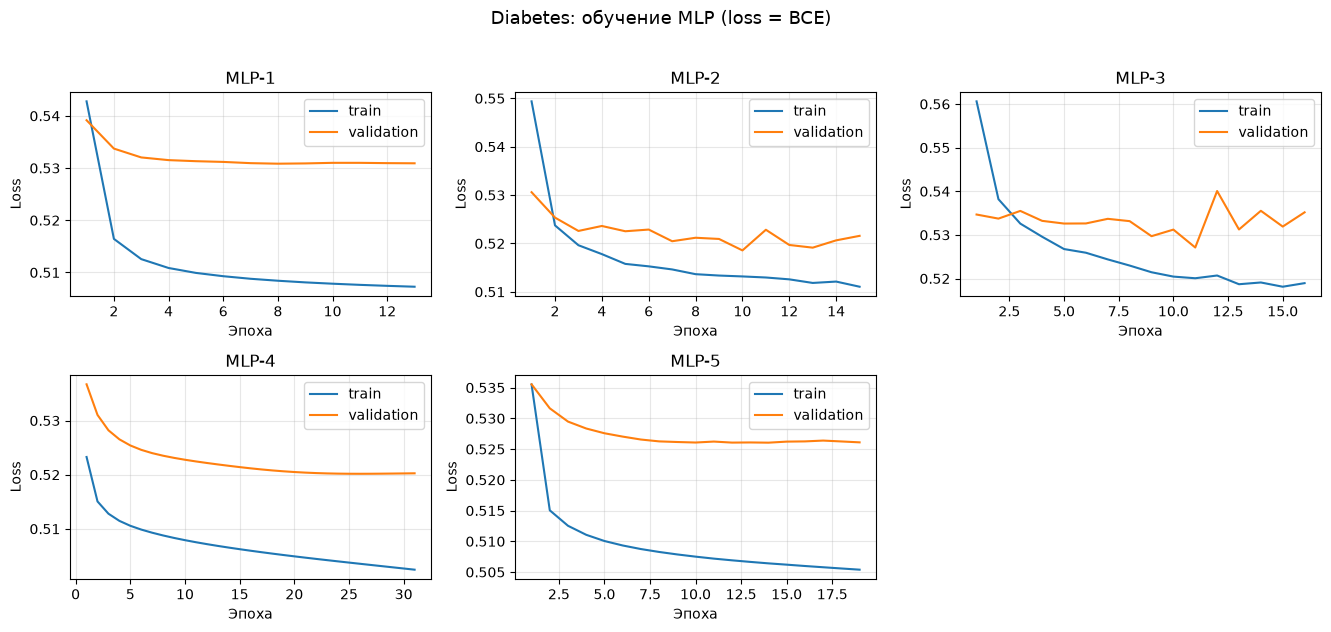

In [ ]:
plot_histories(bin_hist, "Diabetes: обучение MLP (loss = BCE)")

Лучшая модель по Val ROC-AUC: MLP-3, порог = 0.56


Text(0.5, 1.0, 'ROC-кривые (test)')

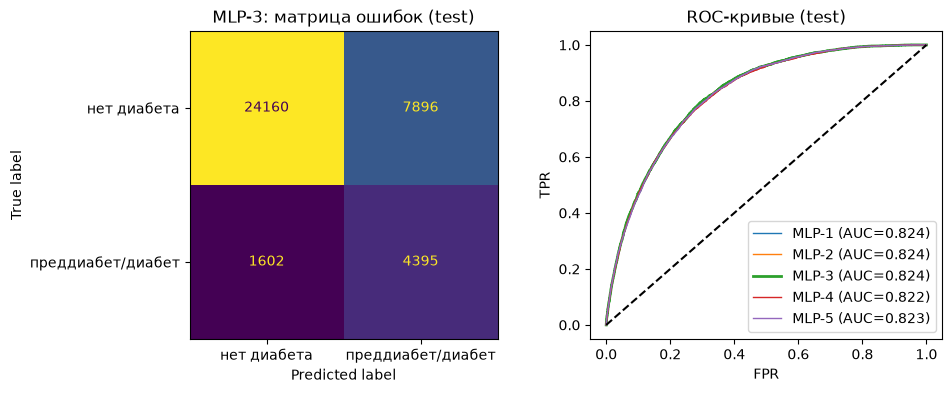

In [ ]:
nn = bin_df[bin_df["Модель"].str.startswith("MLP")]
bname = nn.loc[nn["Val ROC_AUC"].idxmax(), "Модель"]
pva, pte, thr = bin_probs[bname]
print(f"Лучшая модель по Val ROC-AUC: {bname}, порог = {thr:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion_matrix(yte_b, (pte >= thr).astype(int)), display_labels=["нет диабета", "преддиабет/диабет"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title(f"{bname}: матрица ошибок (test)")

for n_, (_, pt_, _) in bin_probs.items():
    f, t, _ = roc_curve(yte_b, pt_); ax[1].plot(f, t, label=f"{n_} (AUC={roc_auc_score(yte_b, pt_):.3f})", lw=2 if n_ == bname else 1)
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(); ax[1].set_title("ROC-кривые (test)")


## 2. Многоклассовая классификация: Body Performance
Классы A, B, C, D кодируются числами; признак `gender` — категориальный (One-Hot).

In [ ]:
body = pd.read_csv("bodyPerformance.csv")
print("Размер:", body.shape, "| пропусков:", int(body.isna().sum().sum()), "| полных дубликатов:", int(body.duplicated().sum()))
print(body.dtypes.to_string())

vc = body["class"].value_counts().sort_index(); print("\nКлассы:\n", pd.DataFrame({"n": vc, "доля": (vc/len(body)).round(4)}))

le = LabelEncoder(); 
y_m = le.fit_transform(body["class"]); CLASSES = list(le.classes_); K = len(CLASSES)
X = body.drop(columns=["class"])      # идентификаторов и признаков с утечкой нет
Xtr_df, Xva_df, Xte_df, ytr_m, yva_m, yte_m = split_dataset(X, y_m, stratify=True)
Xtr_m, Xva_m, Xte_m, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

Размер: (13393, 12) | пропусков: 0 | полных дубликатов: 1
age                        float64
gender                         str
height_cm                  float64
weight_kg                  float64
body fat_%                 float64
diastolic                  float64
systolic                   float64
gripForce                  float64
sit and bend forward_cm    float64
sit-ups counts             float64
broad jump_cm              float64
class                          str

Классы:
           n    доля
class              
A      3348  0.2500
B      3347  0.2499
C      3349  0.2501
D      3349  0.2501
Предобработка завершена:
  Числовых признаков: 10
  Категориальных признаков: 1
  Итоговая размерность матрицы (кол-во колонок): 12


In [ ]:
def multi_eval(y, proba, k):
    pred = proba.argmax(1)
    rep = classification_report(y, pred, target_names=CLASSES, output_dict=True, zero_division=0)
    Y = label_binarize(y, classes=list(range(k)))
    aucs = [roc_auc_score(Y[:, i], proba[:, i]) for i in range(k)]          # One-vs-Rest
    return dict(rep=rep, bal=balanced_accuracy_score(y, pred), aucs=aucs, macro_auc=float(np.mean(aucs)), acc=accuracy_score(y, pred), pred=pred)

def build_mlp(cfg, input_dim, task, n_classes=None):
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    m = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in cfg["hidden"]:
        m.add(layers.Dense(u, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0: m.add(layers.Dropout(cfg["dropout"]))
    if task == "regression":   m.add(layers.Dense(1));                          loss = "mse"
    elif task == "binary":     m.add(layers.Dense(1, activation="sigmoid"));    loss = "binary_crossentropy"
    else:                      m.add(layers.Dense(n_classes, activation="softmax")); loss = "sparse_categorical_crossentropy"
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)}[cfg["opt"]](learning_rate=cfg["lr"])
    m.compile(optimizer=opt, loss=loss)
    return m

dm = DummyClassifier(strategy="prior").fit(Xtr_m, ytr_m)
mc = {"Базовая (Dummy)": multi_eval(yte_m, dm.predict_proba(Xte_m), K)}
mc_val = {"Базовая (Dummy)": multi_eval(yva_m, dm.predict_proba(Xva_m), K)}
mc_hist = {}
mc_proba = {}
mc_models = {}

for cfg in CFGS:
    model = build_mlp(cfg, Xtr_m.shape[1], "multiclass", n_classes=K)
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                         restore_best_weights=True, verbose=0)
    h = model.fit(Xtr_m, ytr_m, validation_data=(Xva_m, yva_m),
                  epochs=200, batch_size=64, callbacks=[es], verbose=0)

    mc_hist[cfg["name"]] = h.history
    mc_models[cfg["name"]] = model
    mc_proba[cfg["name"]] = model.predict(Xte_m, verbose=0)
    
    preds_te = model.predict(Xte_m, verbose=0)
    preds_va = model.predict(Xva_m, verbose=0)
    
    mc[cfg["name"]] = multi_eval(yte_m, preds_te, K)
    mc_val[cfg["name"]] = multi_eval(yva_m, preds_va, K)
    print("[b]", cfg["name"], "готово")

summB = pd.DataFrame([dict(Модель=n,
                           **{"Val BalAcc": mc_val[n]["bal"],
                              "Test Accuracy": r["acc"], "Test BalAcc": r["bal"],
                              "Test macro ROC-AUC (OvR)": r["macro_auc"],
                              "Test macro F1": r["rep"]["macro avg"]["f1-score"]})
                        for n, r in mc.items()])
print(summB.round(4).to_string(index=False))

[b] MLP-1 готово
[b] MLP-2 готово
[b] MLP-3 готово
[b] MLP-4 готово
[b] MLP-5 готово
         Модель  Val BalAcc  Test Accuracy  Test BalAcc  Test macro ROC-AUC (OvR)  Test macro F1
Базовая (Dummy)      0.2500         0.2499       0.2500                    0.5000         0.1000
          MLP-1      0.7461         0.7531       0.7532                    0.9232         0.7517
          MLP-2      0.7456         0.7631       0.7631                    0.9285         0.7612
          MLP-3      0.7516         0.7566       0.7566                    0.9274         0.7544
          MLP-4      0.7491         0.7546       0.7547                    0.9245         0.7519
          MLP-5      0.7436         0.7466       0.7467                    0.9231         0.7411


         Модель       Метрика      A      B      C      D  Macro avg  Weighted avg
Базовая (Dummy)     precision 0.2499 0.0000 0.0000 0.0000     0.0625        0.0624
Базовая (Dummy)        recall 1.0000 0.0000 0.0000 0.0000     0.2500        0.2499
Базовая (Dummy)      f1-score 0.3998 0.0000 0.0000 0.0000     0.1000        0.0999
Базовая (Dummy) ROC-AUC (OvR) 0.5000 0.5000 0.5000 0.5000     0.5000           NaN
          MLP-1     precision 0.7034 0.6538 0.7550 0.9246     0.7592        0.7592
          MLP-1        recall 0.9024 0.6056 0.6740 0.8307     0.7532        0.7531
          MLP-1      f1-score 0.7906 0.6287 0.7122 0.8751     0.7517        0.7516
          MLP-1 ROC-AUC (OvR) 0.9519 0.8788 0.9018 0.9602     0.9232           NaN
          MLP-2     precision 0.6922 0.6765 0.7756 0.9475     0.7729        0.7729
          MLP-2        recall 0.9363 0.5956 0.6938 0.8267     0.7631        0.7631
          MLP-2      f1-score 0.7959 0.6335 0.7324 0.8830     0.7612        0.7612
    

C:\Users\Admin\AppData\Local\Temp\ipykernel_33336\1622875732.py:21: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)


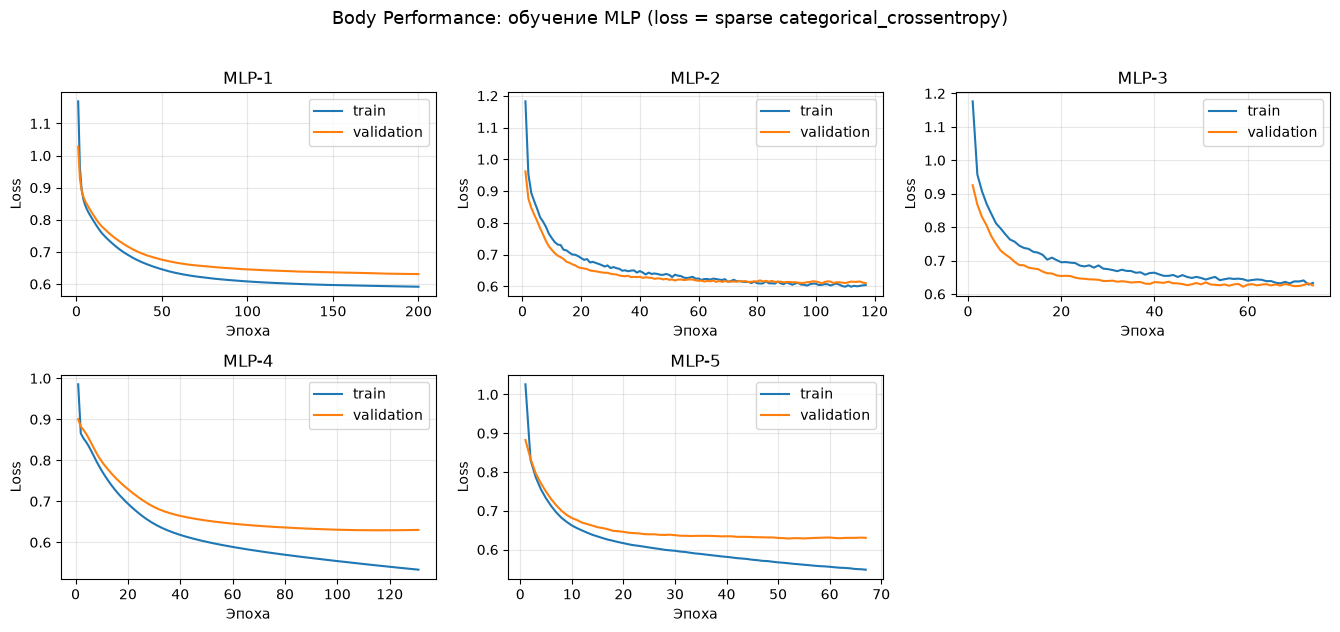

In [ ]:
rows = []
for n, r in mc.items():
    for met in ["precision", "recall", "f1-score"]:
        rows.append({
            "Модель": n,
            "Метрика": met,
            **{c: r["rep"][CLASSES[c]][met] for c in range(K)},
            "Macro avg": r["rep"]["macro avg"][met],
            "Weighted avg": r["rep"]["weighted avg"][met]
        })

    rows.append({
        "Модель": n,
        "Метрика": "ROC-AUC (OvR)",
        **{c: a for c, a in zip(range(K), r["aucs"])},
        "Macro avg": r["macro_auc"],
        "Weighted avg": np.nan
    })

tabB = pd.DataFrame(rows)
tabB.rename(columns={c: CLASSES[c] for c in range(K)}, inplace=True)
print(tabB.round(4).to_string(index=False))

plot_histories(
    mc_hist,
    "Body Performance: обучение MLP (loss = sparse categorical_crossentropy)"
)

Лучшая модель по Val Balanced Accuracy: MLP-3


Text(0.5, 1.0, 'MLP-3: ROC One-vs-Rest (test), macro AUC=0.927')

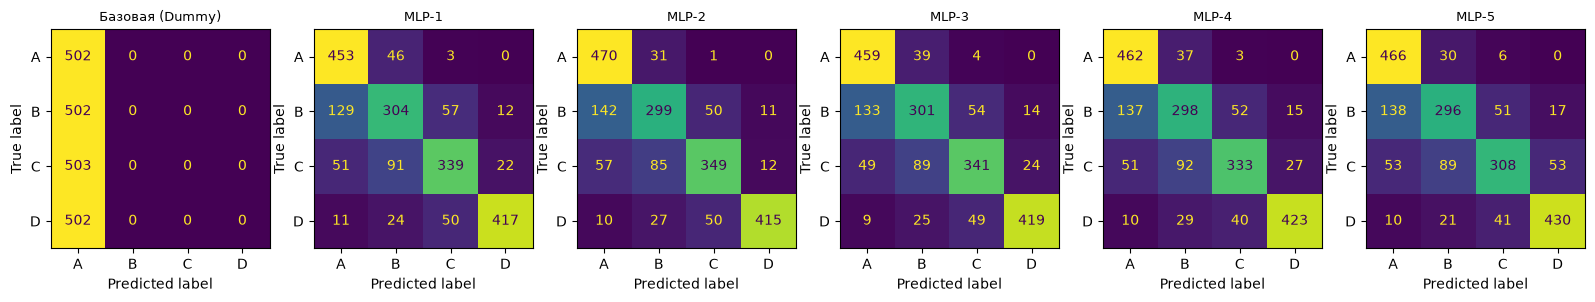

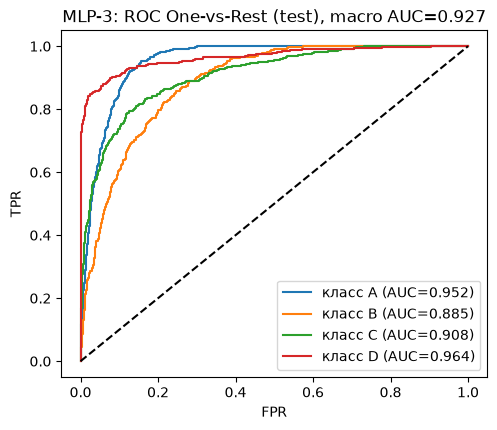

In [ ]:
# Матрицы ошибок всех моделей
names = list(mc.keys()); fig, axs = plt.subplots(1, len(names), figsize=(3.3*len(names), 3.3))
for ax, n in zip(axs, names):
    ConfusionMatrixDisplay(confusion_matrix(yte_m, mc[n]["pred"]), display_labels=CLASSES).plot(ax=ax, colorbar=False); ax.set_title(n, fontsize=9)

# Лучшая модель по Val Balanced Accuracy и её ROC-кривые OvR
nn_names = [n for n in mc if n.startswith("MLP")]; mname = max(nn_names, key=lambda n: mc_val[n]["bal"])
print("Лучшая модель по Val Balanced Accuracy:", mname)
Y = label_binarize(yte_m, classes=list(range(K))); plt.figure(figsize=(5.5, 4.5))
for i, c in enumerate(CLASSES):
    f, t, _ = roc_curve(Y[:, i], mc_proba[mname][:, i]); plt.plot(f, t, label=f"класс {c} (AUC={mc[mname]['aucs'][i]:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.title(f"{mname}: ROC One-vs-Rest (test), macro AUC={mc[mname]['macro_auc']:.3f}")


## 3. Регрессия: Wine Quality (white), целевой признак `quality`

Размер: (1599, 12)

Типы столбцов:
 float64    11
int64       1
Name: count, dtype: int64

Пропуски: 0 | Полных дубликатов строк: 240

Описательная статистика целевого признака:
 count    1599.000
mean        5.636
std         0.808
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         8.000
Name: quality, dtype: float64

Распределение quality:
 quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


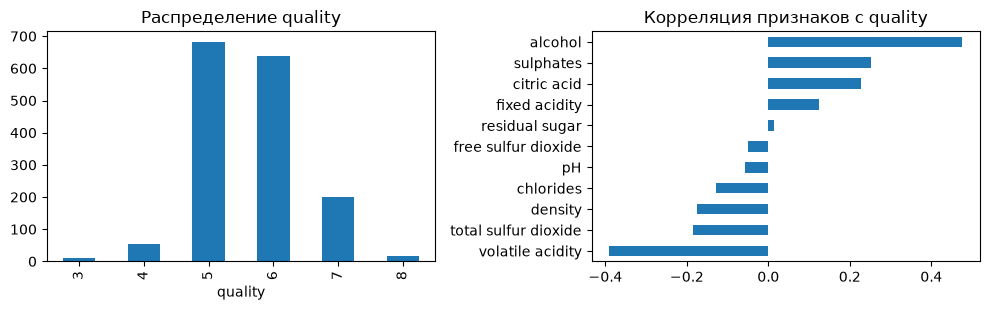

In [6]:
wine = pd.read_csv("winequality-red.csv", sep=";")
print("Размер:", wine.shape); print("\nТипы столбцов:\n", wine.dtypes.value_counts())
print("\nПропуски:", int(wine.isna().sum().sum()), "| Полных дубликатов строк:", int(wine.duplicated().sum()))
print("\nОписательная статистика целевого признака:\n", wine["quality"].describe().round(3))
print("\nРаспределение quality:\n", wine["quality"].value_counts().sort_index())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
wine["quality"].value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение quality")
wine.drop(columns="quality").corrwith(wine["quality"]).sort_values().plot.barh(ax=ax[1], title="Корреляция признаков с quality")
plt.tight_layout()
plt.savefig("reg_eda.png", dpi=300, bbox_inches='tight')

**Утечка и дубликаты.** Идентификаторов и признаков, раскрывающих `quality`, в наборе нет — все 11 признаков физико-химические.
В белом вине много полных дубликатов строк; при случайном разбиении одна и та же строка могла бы попасть и в train, и в test, что завышает
метрики. Поэтому дубликаты удаляются **до разбиения** (`DROP_DUPLICATES = True`). Пропусков нет; импутация всё равно включена в конвейер.
Целевой признак не масштабируется (шкала 3–9), поэтому MSE/MAE сразу в исходных единицах.

In [7]:
df = wine.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df.shape)
X, y = df.drop(columns="quality"), df["quality"].astype("float32")
Xtr_df, Xva_df, Xte_df, ytr, yva, yte = split_dataset(X, y, stratify=False)
Xtr, Xva, Xte, _ = preprocess_datasets(Xtr_df, Xva_df, Xte_df)

После удаления дубликатов: (1359, 12)
Предобработка завершена:
  Числовых признаков: 11
  Категориальных признаков: 0
  Итоговая размерность матрицы (кол-во колонок): 11


In [ ]:
def reg_metrics(y, p):
    return dict(MSE=mean_squared_error(y, p), MAE=mean_absolute_error(y, p), R2=r2_score(y, p))

dummy = DummyRegressor(strategy="mean").fit(Xtr, ytr)
reg_rows, reg_hist, reg_models = [], {}, {}

reg_rows.append(dict(Модель="DummyRegressor", Описание="mean", Эпох="-",
    **{"Train MSE": reg_metrics(ytr, dummy.predict(Xtr))["MSE"], "Val MSE": reg_metrics(yva, dummy.predict(Xva))["MSE"], "Val R2": reg_metrics(yva, dummy.predict(Xva))["R2"]},
    **{f"Test {k}": v for k, v in reg_metrics(yte, dummy.predict(Xte)).items()}))

for cfg0 in CFGS:
    cfg = cfg0 

    # --- построение модели regression ---
    reg = regularizers.l2(cfg["l2"]) if cfg.get("l2", 0) > 0 else None
    model = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
    for u in cfg["hidden"]:
        model.add(layers.Dense(u, activation=cfg["act"], kernel_regularizer=reg))
        if cfg.get("dropout", 0) > 0:
            model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1))
    opt = {"adam": keras.optimizers.Adam,
           "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate=learning_rate, momentum=0.9)}[cfg["opt"]](learning_rate=cfg["lr"])
    model.compile(optimizer=opt, loss="mse")

    # --- обучение ---
    es = callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    h = model.fit(Xtr, ytr, validation_data=(Xva, yva),
                  epochs=200, batch_size=cfg["batch"],
                  callbacks=[es], verbose=0)

    reg_hist[cfg["name"]], reg_models[cfg["name"]] = h.history, model
    P = {k: model.predict(v, verbose=0).ravel() for k, v in dict(tr=Xtr, va=Xva, te=Xte).items()}
    reg_rows.append(dict(Модель=cfg["name"], Эпох=int(np.argmin(h.history["val_loss"]))+1,
        **{"Train MSE": reg_metrics(ytr, P["tr"])["MSE"], "Val MSE": reg_metrics(yva, P["va"])["MSE"], "Val R2": reg_metrics(yva, P["va"])["R2"]},
        **{f"Test {k}": v for k, v in reg_metrics(yte, P["te"]).items()}))
    print(f"{cfg['name']}: лучшая эпоха {reg_rows[-1]['Эпох']}, val MSE={reg_rows[-1]['Val MSE']:.4f}")

reg_df = pd.DataFrame(reg_rows)
reg_df["Переобучение (Val MSE − Train MSE)"] = reg_df["Val MSE"] - reg_df["Train MSE"]
reg_df.round(4).to_csv("table_C_regression_full.csv", index=False)

MLP-1: лучшая эпоха 175, val MSE=0.4097
MLP-2: лучшая эпоха 91, val MSE=0.4314
MLP-3: лучшая эпоха 41, val MSE=0.4738
MLP-4: лучшая эпоха 118, val MSE=0.4325
MLP-5: лучшая эпоха 10, val MSE=0.3885


        Модель Описание Эпох  Train MSE  Val MSE  Val R2  Test MSE  Test MAE  Test R2  Переобучение (Val MSE − Train MSE)
DummyRegressor     mean    -     0.6782   0.7240 -0.0000    0.6296    0.6667  -0.0002                              0.0457
         MLP-1      NaN  175     0.3346   0.4097  0.4341    0.5089    0.5536   0.1915                              0.0751
         MLP-2      NaN   91     0.4041   0.4314  0.4041    0.4086    0.4893   0.3508                              0.0273
         MLP-3      NaN   41     0.4490   0.4738  0.3456    0.4862    0.5271   0.2276                              0.0247
         MLP-4      NaN  118     0.3250   0.4325  0.4026    0.4356    0.5112   0.3079                              0.1075
         MLP-5      NaN   10     0.3637   0.3885  0.4633    0.3905    0.4704   0.3795                              0.0248


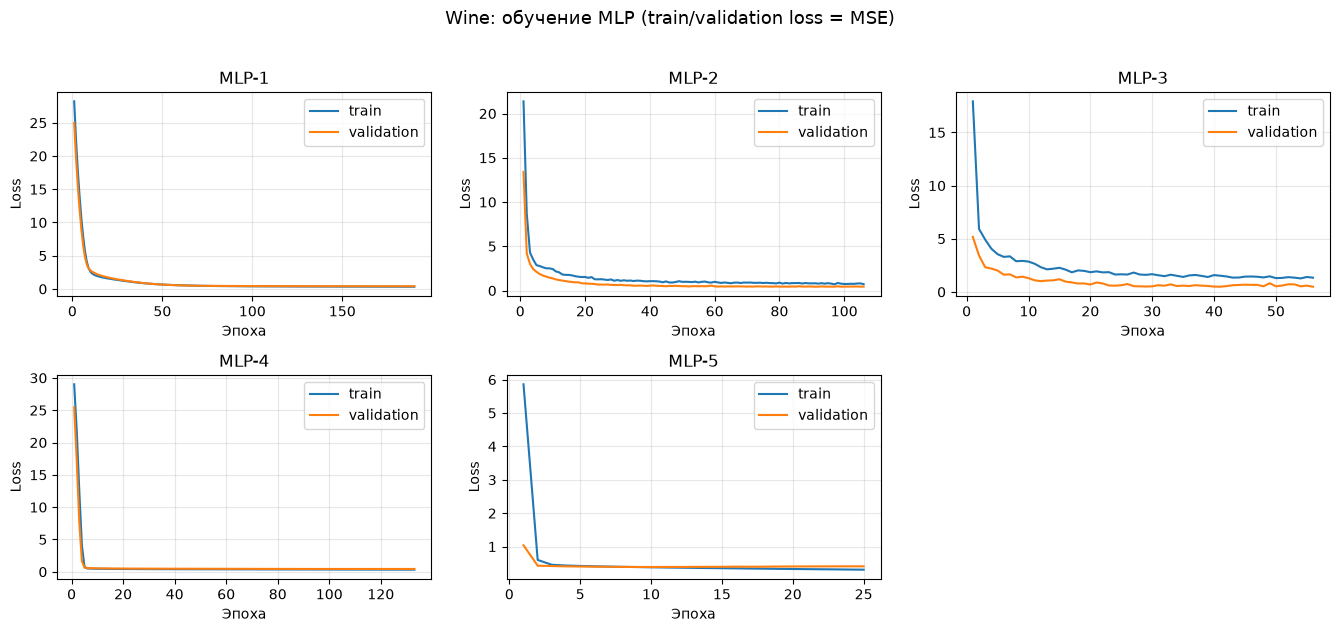

In [10]:
display_cols = ["Модель", "Описание", "Эпох", "Train MSE", "Val MSE", "Val R2", "Test MSE", "Test MAE", "Test R2", "Переобучение (Val MSE − Train MSE)"]
print(reg_df[display_cols].round(4).to_string(index=False))
plot_histories(reg_hist, "Wine: обучение MLP (train/validation loss = MSE)")

Лучшая модель по Val MSE: MLP-5
                   MSE     MAE      R2
MLP (лучшая)    0.3905  0.4704  0.3795
DummyRegressor  0.6296  0.6667 -0.0002


Text(0.5, 0, 'y − ŷ')

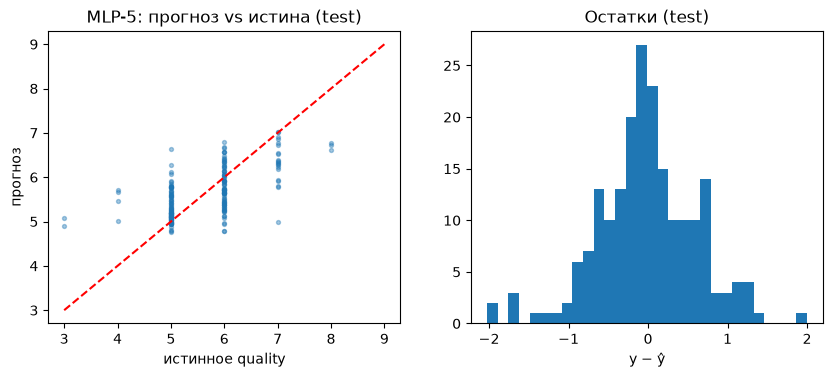

In [11]:
nn = reg_df[reg_df["Модель"].str.startswith("MLP")]
best_name = nn.loc[nn["Val MSE"].idxmin(), "Модель"]

print("Лучшая модель по Val MSE:", best_name)
best = reg_models[best_name]; pte = best.predict(Xte, verbose=0).ravel()
m = reg_metrics(yte, pte); base = reg_metrics(yte, dummy.predict(Xte))

print(pd.DataFrame({"MLP (лучшая)": m, "DummyRegressor": base}).T.round(4))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(yte, pte + np.random.default_rng(SEED).normal(0, .04, len(pte)), s=8, alpha=.4)
ax[0].plot([3, 9], [3, 9], "r--"); ax[0].set_xlabel("истинное quality"); ax[0].set_ylabel("прогноз"); ax[0].set_title(f"{best_name}: прогноз vs истина (test)")
ax[1].hist(yte - pte, bins=30); ax[1].set_title("Остатки (test)"); ax[1].set_xlabel("y − ŷ")

## 4. Выводы

### Регрессия (Wine Quality, white) — результаты выполненного эксперимента
* После удаления 937 дубликатов осталось 3961 объектов; разбиение 70/15/15 → 2772 / 594 / 595 (seed=42).
* Базовая модель (`DummyRegressor`, среднее): Test MSE = 0.786, MAE = 0.672, R² ≈ 0.
* Лучшая по validation — **MLP-2** (64-32, ReLU, Adam, Dropout 0.2): Test MSE = 0.543, MAE = 0.576, **R² = 0.308**.
  Ошибка в среднем около 0.58 балла по шкале качества; MSE снижен примерно на 31 % относительно базовой модели.
* Ориентир R² ≥ 0.80 **не достигнут**. Причины: целевой признак — медиана субъективных оценок экспертов (целые 3–9, сильно сконцентрированы
  вокруг 5–6), 11 физико-химических признаков объясняют только часть дисперсии; в данных есть шум оценок и несбалансированные крайние значения.
  Все пять архитектур дают R² 0.25–0.31, то есть рост глубины/ширины не помогает: MLP-3 (самая глубокая) не лучше MLP-2,
  а MLP-1 (компактная) переобучается сильнее (разрыв Val−Train MSE ≈ 0.10 против 0.05 у MLP-2). Dropout/L2 и Early Stopping уменьшают разрыв.
* Возможные улучшения: постановка как порядковой классификации, градиентный бустинг/Random Forest как сильный бейзлайн, подбор признаков,
  объединение red+white с признаком типа вина.
